In [112]:
import pandas as pd

# Load CSV
data = pd.read_csv("data/Indoor Air Pollution Data.csv", low_memory=False)


In [113]:
data.head()

,NH3,NO2,CO,PM2.5,Temp,Pressure,Humidity,O3,Date,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18
0,0.60,0.16,4.01,0.00,33.53,948.26,51.98,7.37,2020-11-17|11:20:53.407872,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.62,0.15,4.13,0.39,33.5,948.18,51.53,9.06,2020-11-17|11:22:41.214724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.69,0.14,4.45,0.39,33.36,948.15,50.5,16.47,2020-11-17|11:24:28.546567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.70,0.14,4.52,0.38,32.18,948.14,53.35,9.8,2020-11-17|11:26:16.884289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.72,0.14,4.56,0.40,31.77,948.08,53.7,17.28,2020-11-17|11:28:19.820781,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [114]:
# Drop unnamed columns
data.drop(columns=[col for col in data.columns if "Unnamed" in col], inplace=True)

In [115]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173468 entries, 0 to 173467
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   NH3       173465 non-null  float64
 1   NO2       173468 non-null  object 
 2   CO        173465 non-null  float64
 3   PM2.5     173465 non-null  float64
 4   Temp      173465 non-null  object 
 5   Pressure  173465 non-null  object 
 6   Humidity  173465 non-null  object 
 7   O3        173465 non-null  object 
 8   Date      173465 non-null  object 
dtypes: float64(3), object(6)
memory usage: 11.9+ MB


In [116]:
data.describe()

,NH3,CO,PM2.5
count,173465.000000,173465.000000,173465.000000
mean,0.670185,4.339625,0.057456
std,0.177971,1.615590,0.116102
min,0.290000,0.290000,0.000000
25%,0.540000,3.610000,0.000000
50%,0.650000,4.190000,0.000000
75%,0.750000,4.860000,0.000000
max,1.630000,9.920000,0.470000


In [117]:
data.shape

(173468, 9)

In [118]:
print(data.isnull().sum())

NH3         3
NO2         0
CO          3
PM2.5       3
Temp        3
Pressure    3
Humidity    3
O3          3
Date        3
dtype: int64


In [119]:
data.dropna(inplace=True)

In [ ]:
# Remove duplicate rows if any
data = data.drop_duplicates()


In [121]:
# Fix numeric columns with bad characters (like '12.450.73')
for col in data.columns[:-1]:  # skip 'Date' column
    data[col] = data[col].astype(str).str.replace('[^0-9.]', '', regex=True)
    data[col] = data[col].apply(lambda x: x if x.count('.') <= 1 else x.replace('.', '', x.count('.') - 1))  # keep last dot
    data[col] = pd.to_numeric(data[col], errors='coerce')

### Timestamp Parsing
The Date column was parsed into standard datetime format, replacing pipe separators with spaces. Rows with invalid or missing timestamps were removed, and the column was set as the index for time-based analysis.

In [ ]:
# Convert date
data['Date'] = pd.to_datetime(data['Date'].str.replace('|', ' ', regex=False), errors='coerce')
data.dropna(inplace=True)


In [123]:
print(data.columns)

Index(['NH3', 'NO2', 'CO', 'PM2.5', 'Temp', 'Pressure', 'Humidity', 'O3',
       'Date'],
      dtype='object')


### Feature Engineering: Dew Point
Dew point is a derived metric that combines temperature and humidity, giving insight into air moisture levels

In [138]:
# Example: Estimate Dew Point using Temperature and Humidity
import numpy as np
data['DewPoint'] = data['Temp'] - ((100 - data['Humidity']) / 5)
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 169932 entries, 2020-11-17 11:20:53.407872 to 2022-07-14 06:40:39.653879
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   NH3             169932 non-null  float64
 1   NO2             169932 non-null  float64
 2   CO              169932 non-null  float64
 3   PM2.5           169932 non-null  float64
 4   Temp            169932 non-null  float64
 5   Pressure        169932 non-null  float64
 6   Humidity        169932 non-null  float64
 7   O3              169932 non-null  float64
 8   DewPoint        169932 non-null  float64
 9   PM2.5_Category  169932 non-null  object 
 10  Hour            169932 non-null  int32  
dtypes: float64(9), int32(1), object(1)
memory usage: 14.9+ MB


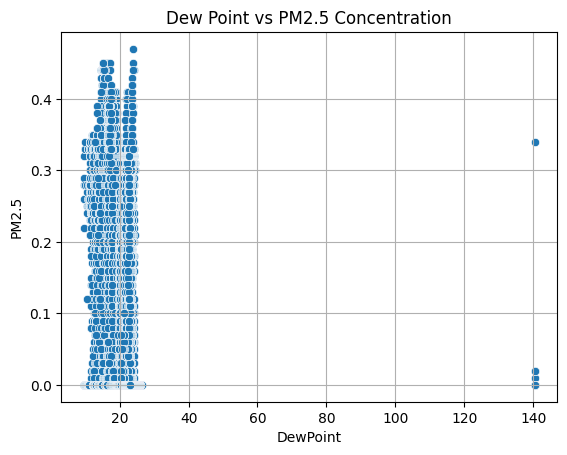

In [139]:
sns.scatterplot(data=data, x='DewPoint', y='PM2.5')
plt.title('Dew Point vs PM2.5 Concentration')
plt.grid(True)
plt.show()


This scatterplot investigates whether moisture content (Dew Point) influences fine particulate matter (PM2.5) levels. Patterns here can inform HVAC system adjustments in humid environments.

<Figure size 1400x700 with 0 Axes>

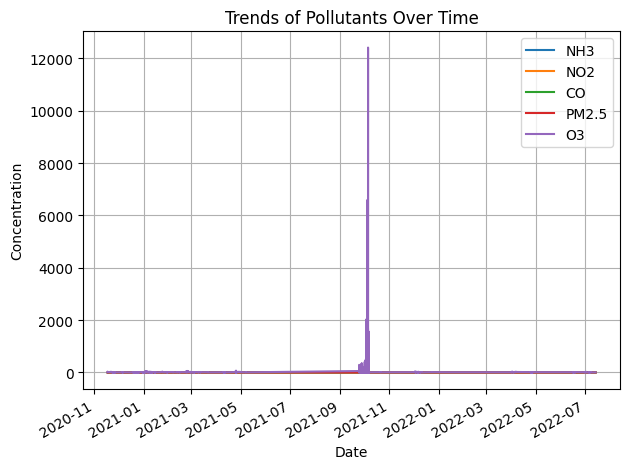

In [140]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 7))
data[['NH3', 'NO2', 'CO', 'PM2.5', 'O3']].plot()
plt.title('Trends of Pollutants Over Time')
plt.ylabel('Concentration')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
# Plot 2: Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Air Quality Variables')
plt.tight_layout()
plt.show()


ValueError: could not convert string to float: 'Good'

<Figure size 1000x800 with 0 Axes>

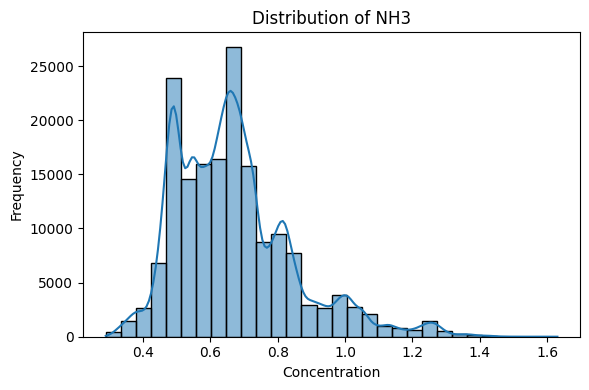

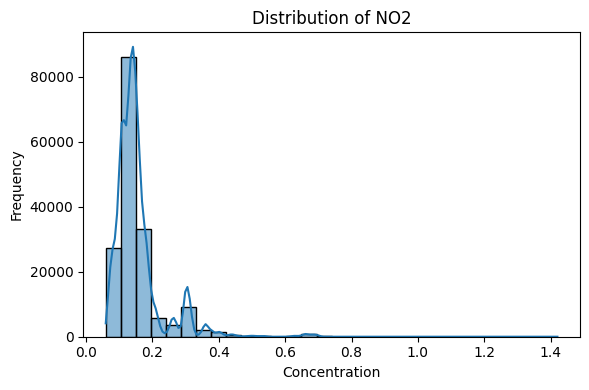

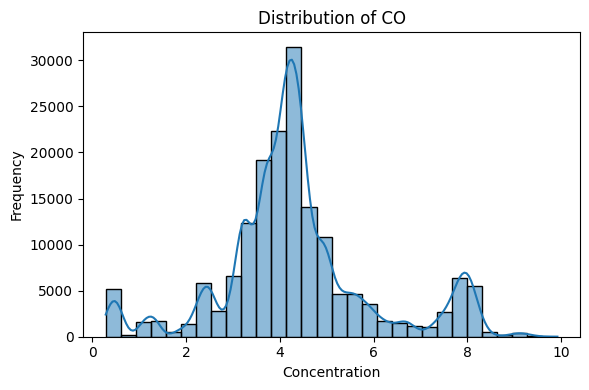

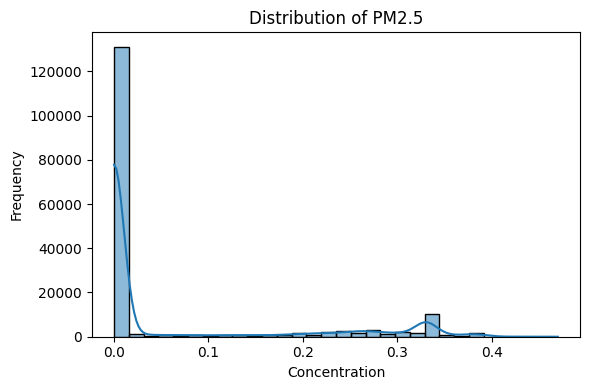

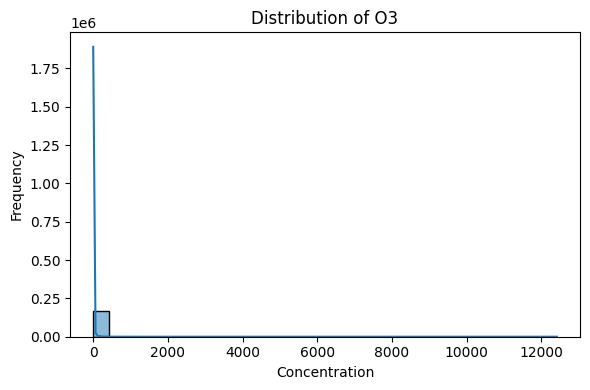

In [ ]:
# Plot 3: Distribution plots of pollutants
pollutants = ['NH3', 'NO2', 'CO', 'PM2.5', 'O3']
for pollutant in pollutants:
    plt.figure(figsize=(6, 4))
    sns.histplot(data[pollutant], kde=True, bins=30)
    plt.title(f'Distribution of {pollutant}')
    plt.xlabel('Concentration')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()


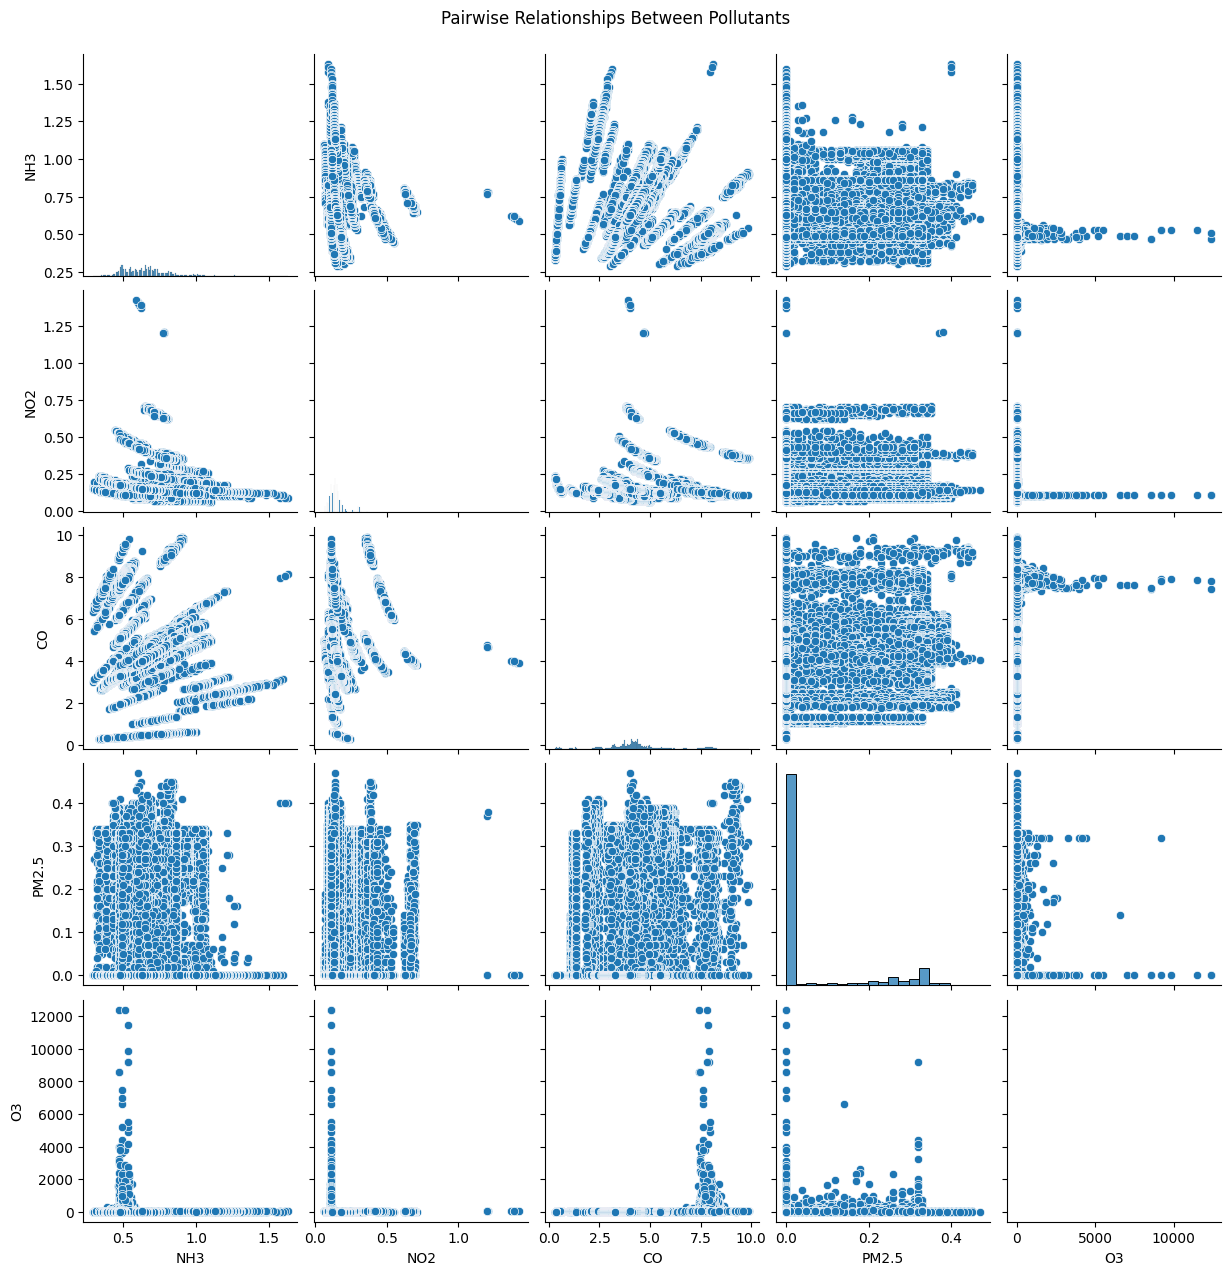

In [ ]:
# Plot 4: Pairplot
sns.pairplot(data[pollutants])
plt.suptitle('Pairwise Relationships Between Pollutants', y=1.02)
plt.show()

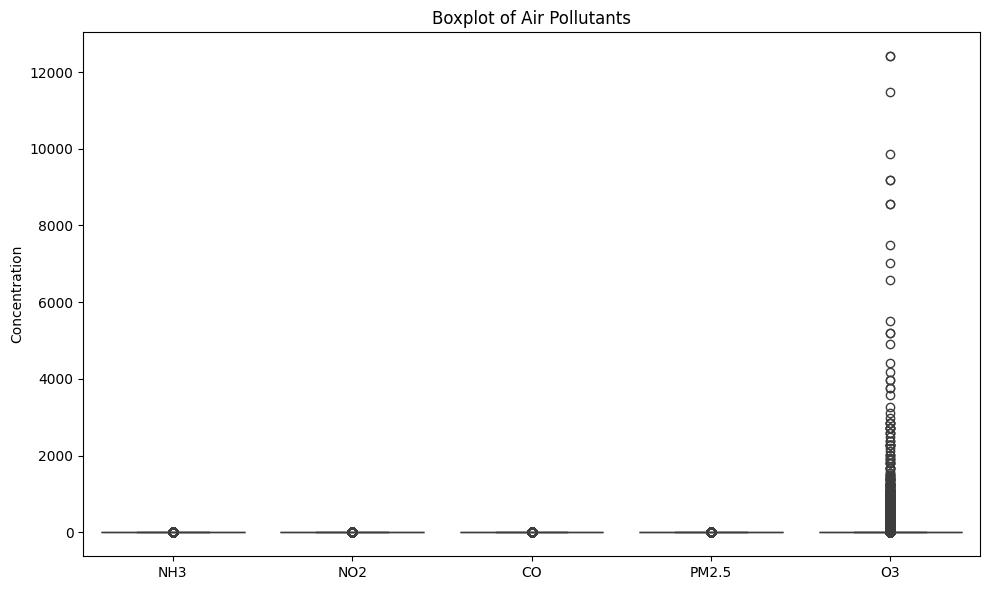

In [ ]:
# Plot 5: Box plots to show spread and outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data[pollutants])
plt.title("Boxplot of Air Pollutants")
plt.ylabel("Concentration")
plt.tight_layout()
plt.show()


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 169932 entries, 0 to 173467
Data columns (total 10 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   NH3       169932 non-null  float64       
 1   NO2       169932 non-null  float64       
 2   CO        169932 non-null  float64       
 3   PM2.5     169932 non-null  float64       
 4   Temp      169932 non-null  float64       
 5   Pressure  169932 non-null  float64       
 6   Humidity  169932 non-null  float64       
 7   O3        169932 non-null  float64       
 8   Date      169932 non-null  datetime64[ns]
 9   DewPoint  169932 non-null  float64       
dtypes: datetime64[ns](1), float64(9)
memory usage: 14.3 MB


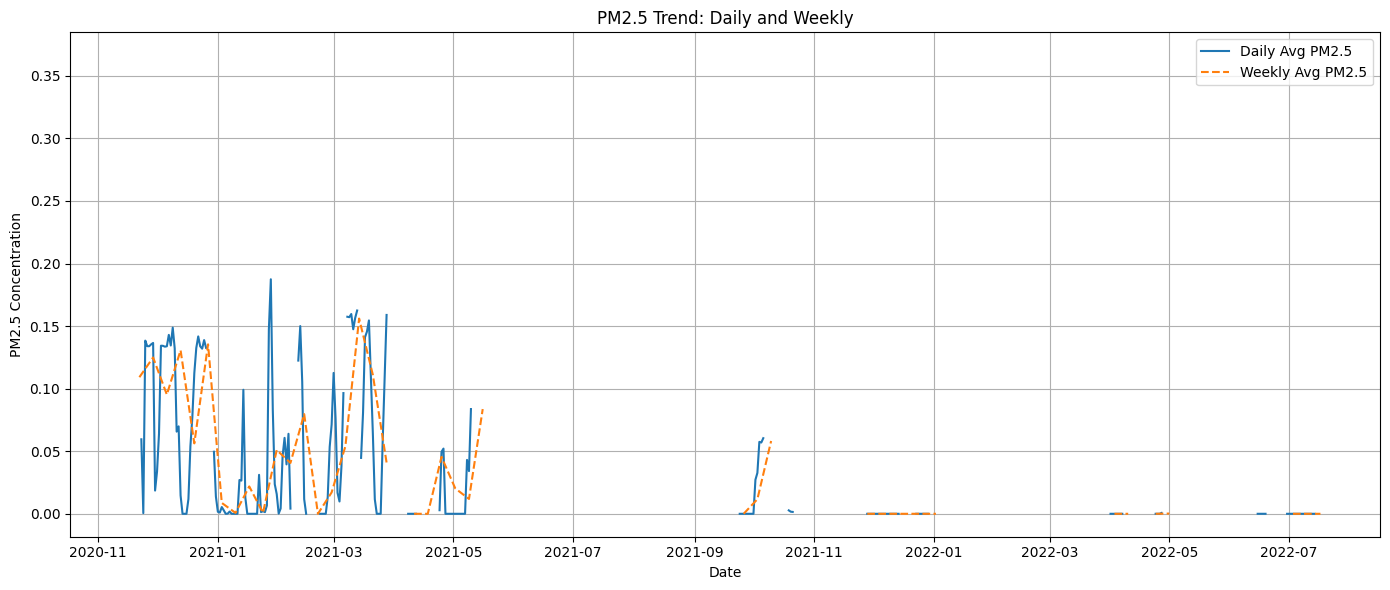

In [ ]:
if 'Date' in data.columns:
    data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
    data = data.set_index('Date')  # Set Date as index
elif data.index.name != 'Date':
    raise ValueError("Date column is missing or not set as index.")

# Drop any rows where Date conversion failed
data = data[~data.index.isna()]

# === 1. PM2.5 Daily and Weekly Trends ===
df_daily = data['PM2.5'].resample('D').mean()
df_weekly = data['PM2.5'].resample('W').mean()

plt.figure(figsize=(14, 6))
plt.plot(df_daily, label='Daily Avg PM2.5')
plt.plot(df_weekly, label='Weekly Avg PM2.5', linestyle='--')
plt.title("PM2.5 Trend: Daily and Weekly")
plt.ylabel("PM2.5 Concentration")
plt.xlabel("Date")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# === 2. AQI Category Pie Chart based on PM2.5 ===
def classify_pm25(value):
    if value <= 12:
        return "Good"
    elif value <= 35.4:
        return "Moderate"
    elif value <= 55.4:
        return "Unhealthy for Sensitive Groups"
    elif value <= 150.4:
        return "Unhealthy"
    elif value <= 250.4:
        return "Very Unhealthy"
    else:
        return "Hazardous"

data['PM2.5_Category'] = data['PM2.5'].apply(classify_pm25)
category_counts = data['PM2.5_Category'].value_counts()


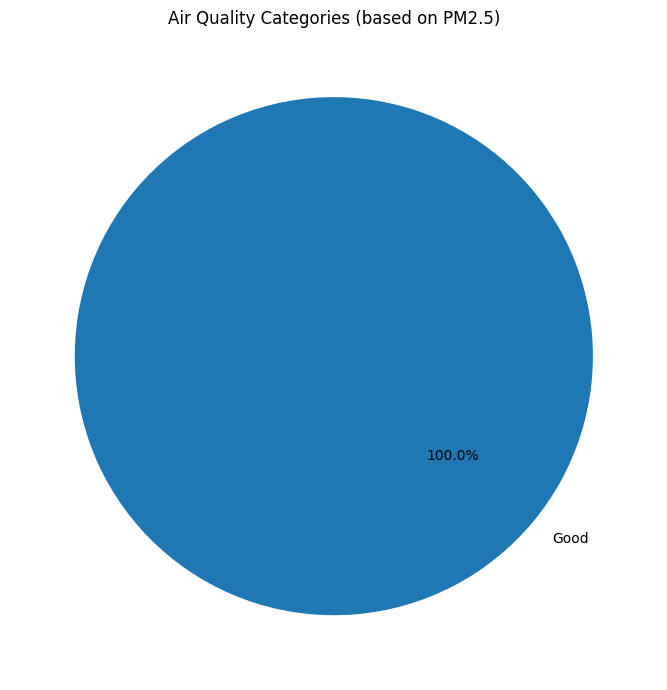

In [ ]:
# Plot Pie Chart
plt.figure(figsize=(7, 7))
category_counts.plot.pie(autopct='%1.1f%%', startangle=140)
plt.title("Air Quality Categories (based on PM2.5)")
plt.ylabel('')
plt.tight_layout()
plt.show()


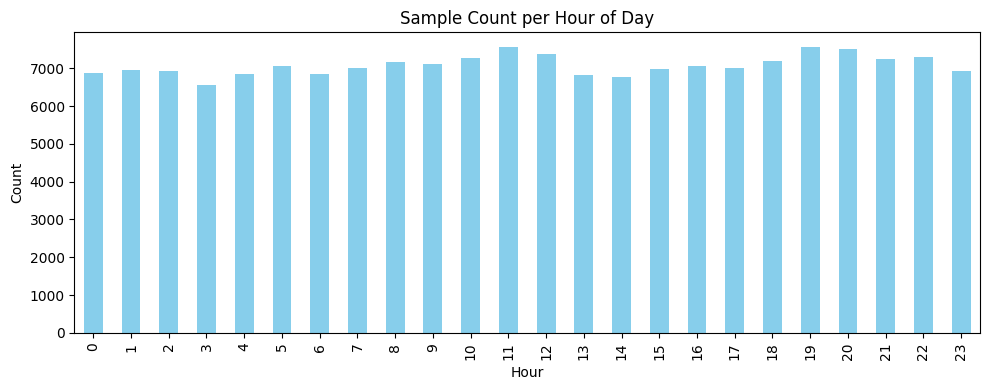

In [ ]:
# --- Sample count by hour ---
data['Hour'] = data.index.hour
plt.figure(figsize=(10, 4))
data['Hour'].value_counts().sort_index().plot(kind='bar', color='skyblue')
plt.title('Sample Count per Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [ ]:
print(data.columns)

Index(['NH3', 'NO2', 'CO', 'PM2.5', 'Temp', 'Pressure', 'Humidity', 'O3',
       'DewPoint', 'PM2.5_Category', 'Hour'],
      dtype='object')


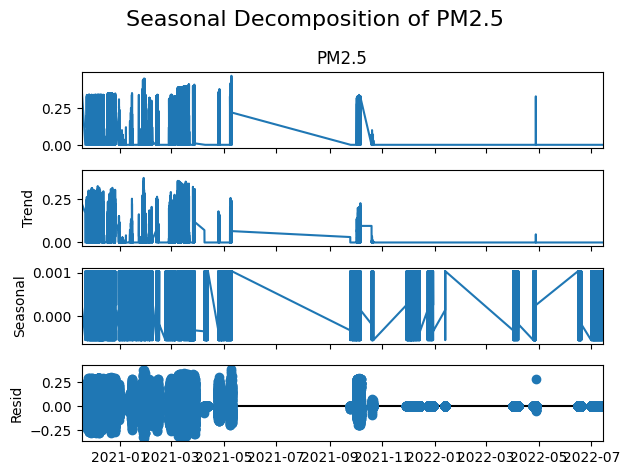

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(data['PM2.5'], model='additive', period=7)
result.plot()
plt.suptitle('Seasonal Decomposition of PM2.5', fontsize=16)
plt.tight_layout()
plt.show()
